# ColdWatch: real-time cold-weather triage on IBM LinuxONE
**Which neighbourhoods need help before the freeze, and what should outreach teams do there?**

Greater Manchester · 1,702 neighbourhoods (LSOAs) · end-to-end pipeline running on IBM Z

| Stage | Model | Runs on |
|---|---|---|
| Who is vulnerable | Weighted index + KMeans archetypes | LinuxONE CPU |
| When it freezes | LSTM 7-day forecast → Monte-Carlo P(trigger) | **Telum on-chip AI accelerator** (`ibm-zdnn-plugin`) |
| Where first | Risk × vulnerability triage | LinuxONE CPU |
| What to do | IBM Granite + BM25 policy retrieval, with guardrail | **Telum on-chip AI accelerator** (llama.cpp zDNN build) |
| Who may see what | AES-256-GCM register, pseudonymised AI inputs | LinuxONE |

This notebook **runs the full pipeline** on the LinuxONE instance: data → models → triage → briefs → interactive map.

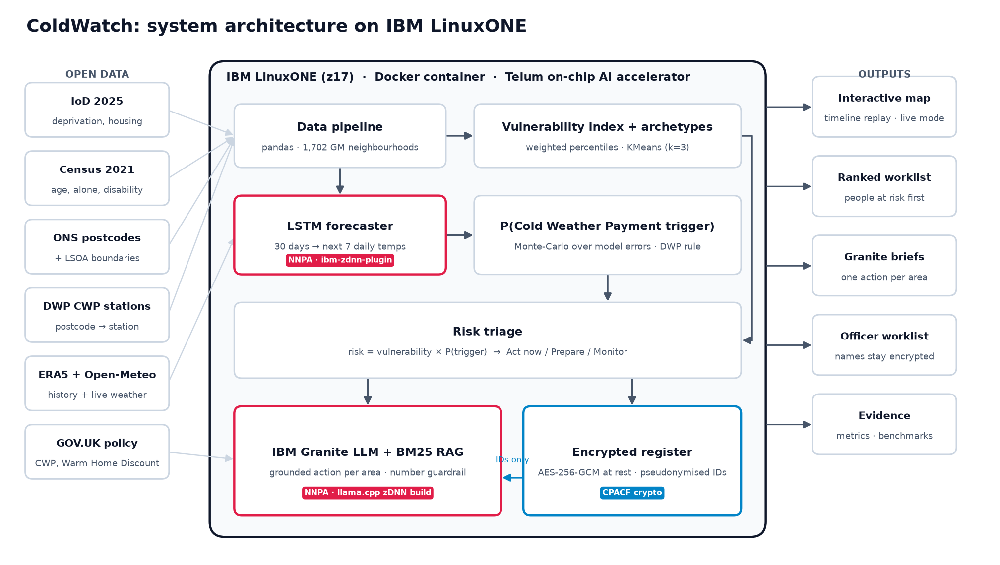

In [1]:
import warnings, json, os, glob, platform, html, importlib.metadata
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Image, HTML, display
from zcold import structural, hazard, scoring, privacy, briefs, mapviz, diagrams
from zcold.paths import PROC, ROOT

REPLAY_DATE  = "2022-12-09"   # a day inside the December 2022 cold spell (unseen test winter)
RUN_TRAINING = True           # retrain the LSTM on IBM Z (~15 s); False = load the saved model
RUN_GRANITE  = True           # regenerate Granite briefs on IBM Z (~1 min); False = load saved briefs

pd.set_option("display.width", 160); pd.set_option("display.max_colwidth", 90)
RED, AMBER, CYAN, SLATE, INK = "#e11d48", "#d97706", "#0284c7", "#64748b", "#0f172a"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "font.size": 10})

diagrams.render_all()
display(Image(str(ROOT / "images/architecture.png")))
%matplotlib inline

### Decision flow: each stage answers one question

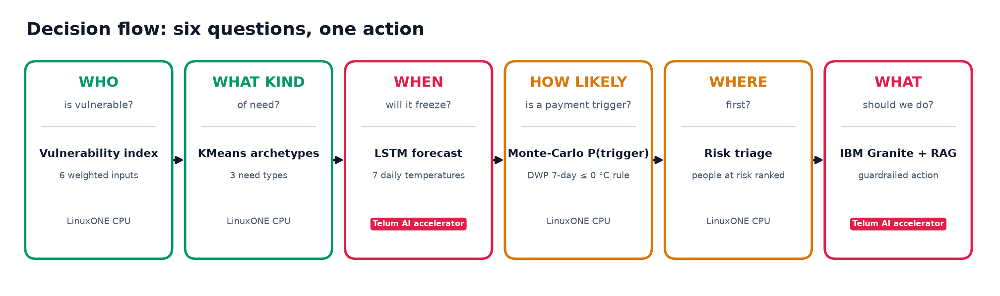

In [2]:
display(Image(str(ROOT / "images/decision_flow.png")))

## 1 · IBM Z hardware acceleration: evidence

| IBM Z capability | Used by | Evidence |
|---|---|---|
| **Telum on-chip AI accelerator (NNPA)** via `ibm-zdnn-plugin` | LSTM forecaster (TensorFlow) | `nnpa` CPU facility; zDNN kernels loaded in the inference process; throughput benchmark (§3) |
| **Telum AI accelerator** via llama.cpp built with `-DGGML_ZDNN=ON` | IBM Granite briefs | `libggml-zdnn` backend library |
| **CPACF on-chip crypto** (Message-Security-Assist) | Platform AES for data at rest | `msa` CPU facility flags |
| **Containerised workload** on LinuxONE | Whole pipeline | `notebook` container; data on a persistent volume |

In [3]:
cpu = open("/proc/cpuinfo").read()
feats = sorted({w for line in cpu.splitlines() if line.startswith("features") for w in line.split(":")[1].split()})
print("Architecture     :", platform.machine(), "|", os.cpu_count(), "CPUs |", platform.platform())
print("NNPA (AI accel.) :", "nnpa" in feats)
print("Crypto (CPACF)   :", [f for f in feats if f.startswith("msa")] or "msa flags not listed")
print("Vector (SIMD)    :", [f for f in feats if f.startswith("vx")])

print("\n-- TensorFlow + ibm-zdnn-plugin (LSTM) --")
print(json.dumps(hazard.accelerator_report(), indent=2))

print("\n-- llama.cpp zDNN build (IBM Granite) --")
print("llama_cpp_python :", importlib.metadata.version("llama_cpp_python"))
for lib in glob.glob("/opt/venv/lib*/python3.12/site-packages/llama_cpp/lib/libggml-zdnn*.so"):
    print("zDNN backend lib :", lib, f"({os.path.getsize(lib) / 1024**2:.1f} MB)")
gguf = briefs.BASE_MODEL
print("Granite model    :", os.path.basename(gguf), "| big-endian GGUF for s390x | magic", open(gguf, "rb").read(4))

Architecture     : s390x | 3 CPUs | Linux-6.8.0-147-generic-s390x-with-glibc2.39
NNPA (AI accel.) : True
Crypto (CPACF)   : ['msa']
Vector (SIMD)    : ['vx', 'vxd', 'vxe', 'vxe2', 'vxp', 'vxp2']

-- TensorFlow + ibm-zdnn-plugin (LSTM) --
{
  "nnpa_in_cpuinfo": true,
  "ibm_zdnn_plugin": "2.3.0",
  "zdnn_kernel_lib": "/opt/venv/lib/python3.12/site-packages/tensorflow/core/kernels/_z_ops.so",
  "tensorflow": "2.18.1",
  "tf_physical_devices": [
    "CPU"
  ]
}

-- llama.cpp zDNN build (IBM Granite) --
llama_cpp_python : 0.3.36
zDNN backend lib : /opt/venv/lib/python3.12/site-packages/llama_cpp/lib/libggml-zdnn.so (0.0 MB)
zDNN backend lib : /opt/venv/lib64/python3.12/site-packages/llama_cpp/lib/libggml-zdnn.so (0.0 MB)
Granite model    : granite-4.0-h-350m-base-be.f16.gguf | big-endian GGUF for s390x | magic b'GGUF'


## 2 · Who is vulnerable: transparent index + archetypes
Six inputs (Census 2021, IoD 2025) → percentile-ranked within Greater Manchester → weighted index (0–100).
Validated against independent official measures; KMeans finds the *type* of need.

Weights: {'pct_75plus': 0.2, 'pct_alone_66plus': 0.2, 'indoors_score': 0.2, 'idaopi_score': 0.15, 'pct_disabled': 0.15, 'pct_no_car': 0.1}

Validation against independent official measures (Spearman):


,benchmark,spearman_rho,p_value
0,fuel_poor_pct,0.32,1.2e-40
1,imd_score,0.33,8.4e-46
2,health_score,0.33,1.6e-43


Silhouette by k: {3: 0.298, 4: 0.237, 5: 0.228, 6: 0.226}


,pct_75plus,pct_alone_66plus,indoors_score,idaopi_score,pct_disabled,pct_no_car,income_score,health_score
A0: disability + poor health,-0.27,0.23,-0.43,0.81,1.12,0.79,0.99,1.05
A1: affluent – very elderly + older people alone,0.65,0.40,-0.12,-0.80,-0.40,-0.82,-0.80,-0.81
A2: younger – poor housing + no car,-0.94,-1.02,0.70,0.62,-0.49,0.69,0.42,0.38


,neighbourhoods,households,mean_vulnerability
archetype,,,
A0: disability + poor health,470,356625.0,58.1
A1: affluent – very elderly + older people alone,808,558658.0,48.0
A2: younger – poor housing + no car,424,315764.0,44.9


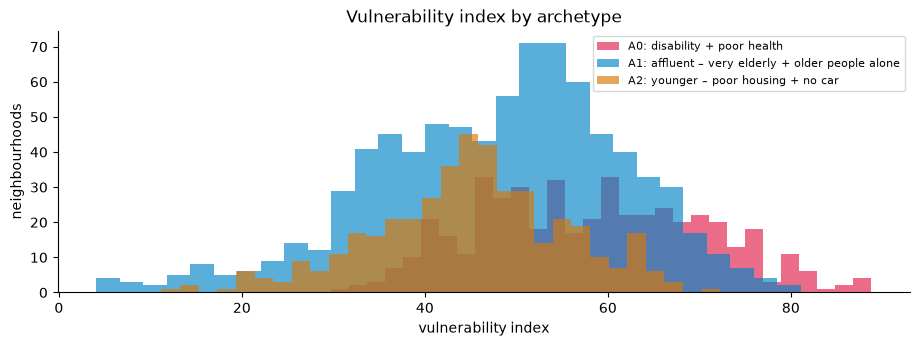

In [4]:
feat = structural.load_features()
vul = structural.vulnerability_index(feat)
print("Weights:", {k: w for k, (w, _) in structural.WEIGHTS.items()})
print("\nValidation against independent official measures (Spearman):")
display(structural.validate(vul))
vul, sil, cent = structural.archetypes(vul)
vul.to_csv(PROC / "lsoa_vulnerability.csv", index=False)
print("Silhouette by k:", {k: round(s, 3) for k, s in sil.items()})
display(cent)
summary = vul.groupby("archetype").agg(neighbourhoods=("lsoa21cd", "size"),
          households=("n_households", "sum"), mean_vulnerability=("vuln_index", "mean")).round(1)
display(summary)

fig, ax = plt.subplots(figsize=(11, 3.4))
for (name, g), col in zip(vul.groupby("archetype"), [RED, CYAN, AMBER]):
    ax.hist(g.vuln_index, bins=30, alpha=.65, color=col, label=name)
ax.set_xlabel("vulnerability index"); ax.set_ylabel("neighbourhoods"); ax.legend(fontsize=8)
ax.set_title("Vulnerability index by archetype"); plt.show()

## 3 · When it freezes: LSTM on the Telum AI accelerator
30 days → each of the next 7 days' mean temperature (residual target). Train ERA5 1991–2019 · validate 2019–22 ·
**test winters 2022–23 → 2025–26 (never seen)**. Monte-Carlo over the model's own correlated errors gives
**P(a Cold Weather Payment window completes in the next 7 days)** using DWP's rule (7-day mean ≤ 0 °C, Nov–Mar).

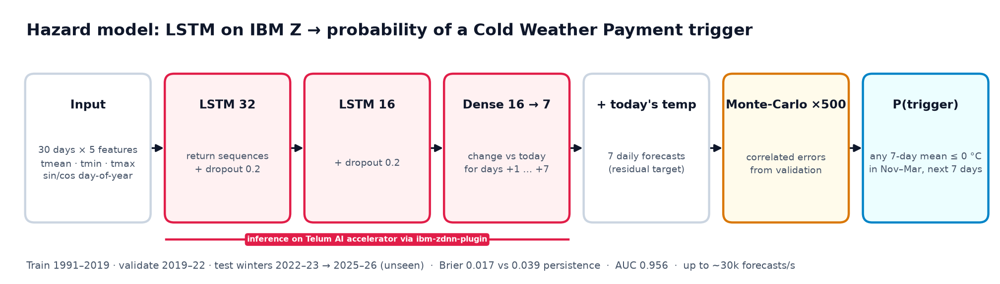

In [5]:
display(Image(str(ROOT / "images/lstm_model.png")))

In [6]:
if RUN_TRAINING:
    hazard.run()                      # trains, evaluates on unseen winters, saves predictions, benchmarks
meta = json.load(open(ROOT / "models/lstm_meta.json")); m = meta["metrics"]

IBM Z accelerator: {
  "nnpa_in_cpuinfo": true,
  "ibm_zdnn_plugin": "2.3.0",
  "zdnn_kernel_lib": "/opt/venv/lib/python3.12/site-packages/tensorflow/core/kernels/_z_ops.so",
  "tensorflow": "2.18.1",
  "tf_physical_devices": [
    "CPU"
  ]
}
Stations: ['Rochdale', 'Rostherne'] | rows 26,134 | 1991-01-01 .. 2026-10-10
Sequences: train 20,806 | val 2,178 | test 3,050
Epoch 1/20
82/82 - 5s - 64ms/step - loss: 9.5442 - mae: 2.3852 - val_loss: 9.4530 - val_mae: 2.3611
Epoch 2/20
82/82 - 2s - 21ms/step - loss: 8.4013 - mae: 2.2444 - val_loss: 8.7020 - val_mae: 2.2669
Epoch 3/20
82/82 - 2s - 22ms/step - loss: 6.9721 - mae: 2.0622 - val_loss: 8.6729 - val_mae: 2.2631
Epoch 4/20
82/82 - 2s - 21ms/step - loss: 6.6825 - mae: 2.0269 - val_loss: 8.7120 - val_mae: 2.2682
Epoch 5/20
82/82 - 2s - 20ms/step - loss: 6.5972 - mae: 2.0156 - val_loss: 8.7562 - val_mae: 2.2745
Epoch 6/20
82/82 - 2s - 21ms/step - loss: 6.5417 - mae: 2.0077 - val_loss: 8.7869 - val_mae: 2.2788
Epoch 7/20
82/82 - 2s - 23ms/s

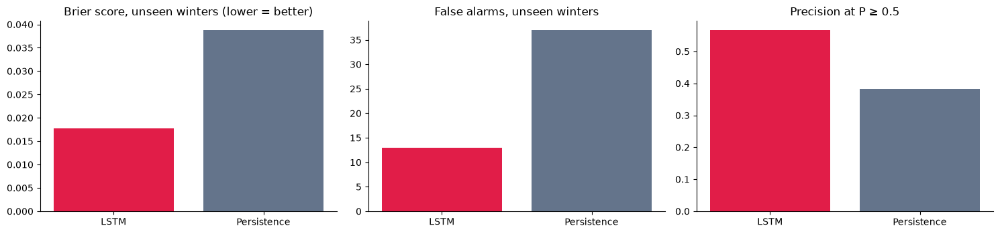

AUC 0.973 · LSTM {'precision': 0.567, 'recall': 0.515, 'TP': 17, 'FP': 13, 'FN': 16} · persistence {'precision': 0.383, 'recall': 0.697, 'TP': 23, 'FP': 37, 'FN': 10}


In [7]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
ax[0].bar(["LSTM", "Persistence"], [m["brier_lstm"], m["brier_persistence"]], color=[RED, SLATE])
ax[0].set_title("Brier score, unseen winters (lower = better)")
ax[1].bar(["LSTM", "Persistence"], [m["lstm_at_0.5"]["FP"], m["persistence"]["FP"]], color=[RED, SLATE])
ax[1].set_title("False alarms, unseen winters")
ax[2].bar(["LSTM", "Persistence"], [m["lstm_at_0.5"]["precision"], m["persistence"]["precision"]], color=[RED, SLATE])
ax[2].set_title("Precision at P ≥ 0.5")
plt.tight_layout(); plt.show()
print(f"AUC {m['auc_lstm']} · LSTM {m['lstm_at_0.5']} · persistence {m['persistence']}")

### Inference throughput on the Telum AI accelerator

zDNN libraries loaded in this inference process:
  /opt/venv/lib/python3.12/site-packages/tensorflow/core/kernels/_z_ops.so
  /usr/local/lib/libzdnn.so.0


,batch,median_ms,sequences_per_s
0,1,75.93,13
1,100,78.05,1281
2,1000,111.04,9005
3,10000,299.73,33363


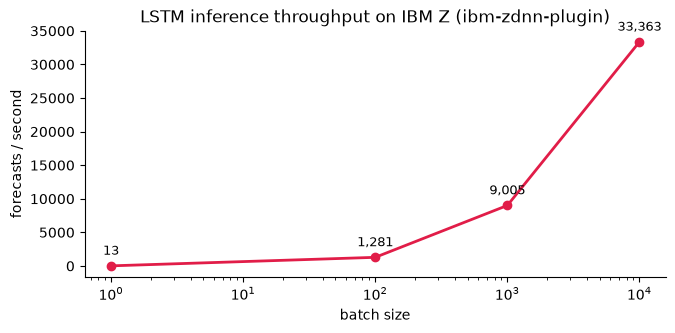

In [8]:
import tensorflow as tf
model = tf.keras.models.load_model(ROOT / "models/lstm_tmean7.keras")
model(np.zeros((1, 30, 5), "float32"))
libs = sorted({l.split()[-1] for l in open("/proc/self/maps") if "zdnn" in l.lower() or "_z_ops" in l})
print("zDNN libraries loaded in this inference process:", *libs, sep="\n  ")
bench = hazard.benchmark(model)
display(bench)
fig, ax = plt.subplots(figsize=(7.5, 3.2))
ax.plot(bench.batch, bench.sequences_per_s, "o-", color=RED, lw=2)
for x, y in zip(bench.batch, bench.sequences_per_s): ax.annotate(f"{y:,}", (x, y), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=9)
ax.set_xscale("log"); ax.set_xlabel("batch size"); ax.set_ylabel("forecasts / second")
ax.set_title("LSTM inference throughput on IBM Z (ibm-zdnn-plugin)"); plt.show()

## 4 · Replay: the December 2022 cold spell (unseen test winter)

,station,freezing week completed,Prepare from,Prepare lead (days),Act now from,Act lead (days)
0,Rochdale,2022-12-12,2022-12-07,5,2022-12-09,3
1,Rostherne,2022-12-13,2022-12-09,4,2022-12-12,1


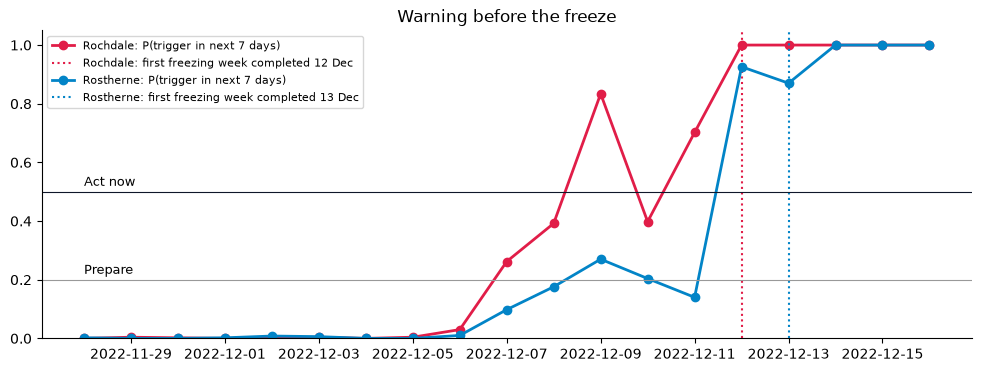

In [9]:
preds = pd.read_csv(PROC / "hazard_test_predictions.csv", parse_dates=["date"])
lab = pd.read_csv(PROC / "cwp_labels.csv", parse_dates=["date"])
rows = []
for st in sorted(preds.station_name.unique()):
    done = lab[(lab.station_name == st) & (lab.date >= "2022-12-01") & (lab.roll7_mean <= 0)].date.min()
    g = preds[(preds.station_name == st) & (preds.date >= "2022-11-25") & (preds.date < done)]
    prep, act = g[g.p_trigger >= .2].date.min(), g[g.p_trigger >= .5].date.min()
    rows.append({"station": st, "freezing week completed": done.date(),
                 "Prepare from": prep.date() if pd.notna(prep) else None, "Prepare lead (days)": (done - prep).days if pd.notna(prep) else None,
                 "Act now from": act.date() if pd.notna(act) else None, "Act lead (days)": (done - act).days if pd.notna(act) else None})
lead = pd.DataFrame(rows); display(lead)

win = preds[(preds.date >= "2022-11-28") & (preds.date <= "2022-12-16")]
fig, ax = plt.subplots(figsize=(12, 4))
for (st, g), c in zip(win.groupby("station_name"), [RED, CYAN]):
    ax.plot(g.date, g.p_trigger, "o-", color=c, lw=2, label=f"{st}: P(trigger in next 7 days)")
    d = lead.set_index("station").loc[st, "freezing week completed"]
    ax.axvline(pd.Timestamp(d), color=c, ls=":", lw=1.5, label=f"{st}: first freezing week completed {d:%d %b}")
ax.axhline(.5, color=INK, lw=.8); ax.text(win.date.min(), .52, "Act now", fontsize=9)
ax.axhline(.2, color="#999", lw=.8); ax.text(win.date.min(), .22, "Prepare", fontsize=9)
ax.set_ylim(0, 1.05); ax.legend(fontsize=8, loc="upper left"); ax.set_title("Warning before the freeze")
plt.show()

In [10]:
risk = scoring.run(REPLAY_DATE)

Hazard source: REPLAY as of 2022-12-09
station_name  p_trigger_7d  pred_tmean_7d  label
    Rochdale         0.834           0.28    1.0
   Rostherne         0.270           2.03    1.0

Triage summary:
              lsoas  households  mean_risk
priority                                 
1 - Act now    268    195911.0       52.8
2 - Prepare    411    303860.0       17.0
3 - Monitor   1023    731276.0       18.3

Top 10 priority areas:
      lsoa21nm station_name  risk_score  vuln_index  p_trigger_7d                                        archetype                          driver_1  n_households    priority
  Oldham 020E     Rochdale        54.9        65.8         0.834 A1: affluent – very elderly + older people alone many people aged 66+ living alone        1122.0 1 - Act now
Rochdale 018B     Rochdale        68.1        81.6         0.834                     A0: disability + poor health many people aged 66+ living alone        1036.0 1 - Act now
Tameside 005A     Rochdale        67.5 

## 5 · Privacy: the mainframe holds identities, the AI receives pseudonyms

In [11]:
privacy.run(REPLAY_DATE)
print("\nEncrypted at rest:", *[f"{p.name}  ({p.stat().st_size / 1024:.0f} KB)" for p in sorted((ROOT / "data/secure").glob("*.enc"))], sep="\n  ")

Crypto backend: AES-256-GCM (pycryptodome)
Decrypted in memory only. 1,450 registered residents are in 'Act now' areas.
Officer worklist (identifiable) -> /home/ibm-user/shared/zcold/data/secure/worklist_2022-12-09.enc [encrypted]

WHAT THE MAINFRAME HOLDS (first 3, synthetic):
           name        phone postcode  age  medical_equipment
    Derek Lewis 07700 900569   BL67NH   86              False
 Patricia Green 07700 900648   BL67JD   96              False
Michael Roberts 07700 900974   BL67JJ   72              False

WHAT GRANITE RECEIVES (pseudonymised):
household_ref    lsoa21nm   age  medical_equipment  pension_credit
HH-8c2d407ff2 Bolton 004B   80+              False           False
HH-e450292cd0 Bolton 004B   80+              False            True
HH-a583e3c7e5 Bolton 004B 66-79              False           False

Aggregated per area for briefs:
                registered_at_risk  aged_80plus  medical_equipment
lsoa21nm                                                         

## 6 · What to do: IBM Granite briefs on the Telum AI accelerator
Code writes every number; Granite writes one action line per area, grounded in retrieved policy text.
A guardrail rejects any number not present in the source facts and substitutes an approved action.

In [12]:
if RUN_GRANITE:
    briefs.run(REPLAY_DATE)
b = pd.read_csv(PROC / f"briefs_{REPLAY_DATE}.csv")
print(f"\nGranite: {b.gen_tokens.sum()} tokens in {b.gen_seconds.sum():.1f}s · guardrail outcomes:",
      b.guardrail.value_counts().to_dict() if "guardrail" in b else "n/a")

Briefing 5 areas (3 need types) from lsoa_risk_replay_2022-12-09.csv
Loading Granite: granite-4.0-h-350m-base-be.f16.gguf (llama.cpp zDNN build, 3 threads)


llama_kv_cache: the V embeddings have different sizes across layers and FA is not enabled - padding V cache to 256



[ACT NOW] Oldham 020E (Oldham) - freeze chance 83%, vulnerability 66/100
Why: many people aged 66+ living alone; high share of residents aged 75+. Need type: affluent – very elderly + older people alone.
Reach: ~1122 households, ~233 older people living alone.
Action (Granite): Target homes with poor heating, give advice on running the home affordably and signpost warm spaces.
Sources: cold_weather_payment.txt
  (generated in 10.75s, 20 tokens)

[ACT NOW] Rochdale 018B (Rochdale) - freeze chance 83%, vulnerability 82/100
Why: many people aged 66+ living alone; high disability rate. Need type: disability + poor health.
Reach: ~1036 households, ~230 older people living alone.
Action (Granite): Make welfare calls to older people living alone, check the heating is on and food supplies are in. Signpost warm spaces.
Sources: cold_weather_payment.txt, warm_home_discount_guide.txt
  (generated in 10.51s, 25 tokens)

[ACT NOW] Bolton 022E (Bolton) - freeze chance 83%, vulnerability 55/100
Why:

## 7 · The operational view: interactive map
Press **Play** on the timeline to replay 1–14 December 2022 · hover an area for detail · click a numbered pin for its Granite brief.

In [13]:
def embed(fmap, name, height=760):
    """Save the map and embed it as a self-contained, playable frame."""
    (ROOT / "outputs").mkdir(exist_ok=True)
    fmap.save(str(ROOT / "outputs" / name))
    doc = html.escape(fmap.get_root().render(), quote=True)
    return HTML(f'<iframe srcdoc="{doc}" style="width:100%;height:{height}px;border:0;border-radius:12px"></iframe>')

embed(mapviz.build(REPLAY_DATE), f"coldwatch_map_{REPLAY_DATE}.html")

### Live: this week, looking forward

In [14]:
try:
    live_map = embed(mapviz.build("live"), "coldwatch_map_live.html")
except Exception as e:
    live_map = HTML(f"<p>Live forecast unavailable: {e}</p>")
live_map

station_name forecast_date  p_trigger_7d  pred_tmean_7d
    Rochdale    2026-10-17           0.0           9.45
   Rostherne    2026-10-17           0.0           8.99


## Impact

In [15]:
act = risk[risk.priority.str.startswith("1")]
alone = (act.pct_alone_66plus / 100 * act.n_households).sum()
best = lead.sort_values("Prepare lead (days)", ascending=False).iloc[0]
print(f"{REPLAY_DATE} · Act now: {len(act)} neighbourhoods · ~{alone:,.0f} older people living alone")
print(f"Warning: {best.station} area on Prepare {best['Prepare lead (days)']} days and Act now "
      f"{best['Act lead (days)']} days before the first freezing week completed")
print(f"Forecast skill (unseen winters): Brier {m['brier_lstm']} vs {m['brier_persistence']} persistence · "
      f"AUC {m['auc_lstm']} · false alarms {m['lstm_at_0.5']['FP']} vs {m['persistence']['FP']}")
print(f"Throughput on IBM Z: up to {bench.sequences_per_s.max():,} forecasts/s · "
      f"same pipeline scales to all 33,755 English neighbourhoods")

2022-12-09 · Act now: 268 neighbourhoods · ~29,405 older people living alone
Forecast skill (unseen winters): Brier 0.0178 vs 0.0388 persistence · AUC 0.973 · false alarms 13 vs 37
Throughput on IBM Z: up to 33,363 forecasts/s · same pipeline scales to all 33,755 English neighbourhoods


*Help that arrives before the cold does.*